In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 60)
sns.set_style("whitegrid")
RANDOM_STATE = 42   # fixed number so your results are the same every run

In [4]:
df = pd.read_csv("cumulative.csv")

print("Shape (rows, columns):", df.shape)
print()
print(df.columns.tolist())

Shape (rows, columns): (9564, 50)

['rowid', 'kepid', 'kepoi_name', 'kepler_name', 'koi_disposition', 'koi_pdisposition', 'koi_score', 'koi_fpflag_nt', 'koi_fpflag_ss', 'koi_fpflag_co', 'koi_fpflag_ec', 'koi_period', 'koi_period_err1', 'koi_period_err2', 'koi_time0bk', 'koi_time0bk_err1', 'koi_time0bk_err2', 'koi_impact', 'koi_impact_err1', 'koi_impact_err2', 'koi_duration', 'koi_duration_err1', 'koi_duration_err2', 'koi_depth', 'koi_depth_err1', 'koi_depth_err2', 'koi_prad', 'koi_prad_err1', 'koi_prad_err2', 'koi_teq', 'koi_teq_err1', 'koi_teq_err2', 'koi_insol', 'koi_insol_err1', 'koi_insol_err2', 'koi_model_snr', 'koi_tce_plnt_num', 'koi_tce_delivname', 'koi_steff', 'koi_steff_err1', 'koi_steff_err2', 'koi_slogg', 'koi_slogg_err1', 'koi_slogg_err2', 'koi_srad', 'koi_srad_err1', 'koi_srad_err2', 'ra', 'dec', 'koi_kepmag']


In [5]:
df.head()

,rowid,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_fpflag_ec,koi_period,koi_period_err1,koi_period_err2,koi_time0bk,koi_time0bk_err1,koi_time0bk_err2,koi_impact,koi_impact_err1,koi_impact_err2,koi_duration,koi_duration_err1,koi_duration_err2,koi_depth,koi_depth_err1,koi_depth_err2,koi_prad,koi_prad_err1,koi_prad_err2,koi_teq,koi_teq_err1,koi_teq_err2,koi_insol,koi_insol_err1,koi_insol_err2,koi_model_snr,koi_tce_plnt_num,koi_tce_delivname,koi_steff,koi_steff_err1,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
0,1,10797460,K00752.01,Kepler-227 b,CONFIRMED,CANDIDATE,1.000,0,0,0,0,9.488036,2.775000e-05,-2.775000e-05,170.538750,0.002160,-0.002160,0.146,0.318,-0.146,2.95750,0.08190,-0.08190,615.8,19.5,-19.5,2.26,0.26,-0.15,793.0,NaN,NaN,93.59,29.45,-16.65,35.8,1.0,q1_q17_dr25_tce,5455.0,81.0,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
1,2,10797460,K00752.02,Kepler-227 c,CONFIRMED,CANDIDATE,0.969,0,0,0,0,54.418383,2.479000e-04,-2.479000e-04,162.513840,0.003520,-0.003520,0.586,0.059,-0.443,4.50700,0.11600,-0.11600,874.8,35.5,-35.5,2.83,0.32,-0.19,443.0,NaN,NaN,9.11,2.87,-1.62,25.8,2.0,q1_q17_dr25_tce,5455.0,81.0,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
2,3,10811496,K00753.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,0,19.899140,1.494000e-05,-1.494000e-05,175.850252,0.000581,-0.000581,0.969,5.126,-0.077,1.78220,0.03410,-0.03410,10829.0,171.0,-171.0,14.60,3.92,-1.31,638.0,NaN,NaN,39.30,31.04,-10.49,76.3,1.0,q1_q17_dr25_tce,5853.0,158.0,-176.0,4.544,0.044,-0.176,0.868,0.233,-0.078,297.00482,48.134129,15.436
3,4,10848459,K00754.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,0,1.736952,2.630000e-07,-2.630000e-07,170.307565,0.000115,-0.000115,1.276,0.115,-0.092,2.40641,0.00537,-0.00537,8079.2,12.8,-12.8,33.46,8.50,-2.83,1395.0,NaN,NaN,891.96,668.95,-230.35,505.6,1.0,q1_q17_dr25_tce,5805.0,157.0,-174.0,4.564,0.053,-0.168,0.791,0.201,-0.067,285.53461,48.285210,15.597
4,5,10854555,K00755.01,Kepler-664 b,CONFIRMED,CANDIDATE,1.000,0,0,0,0,2.525592,3.761000e-06,-3.761000e-06,171.595550,0.001130,-0.001130,0.701,0.235,-0.478,1.65450,0.04200,-0.04200,603.3,16.9,-16.9,2.75,0.88,-0.35,1406.0,NaN,NaN,926.16,874.33,-314.24,40.9,1.0,q1_q17_dr25_tce,6031.0,169.0,-211.0,4.438,0.070,-0.210,1.046,0.334,-0.133,288.75488,48.226200,15.509


In [6]:
# How many objects in each class?
print(df["koi_disposition"].value_counts())
print()
print(df["koi_disposition"].value_counts(normalize=True).round(3))

# Which columns have the most missing values?
print()
print(df.isna().mean().sort_values(ascending=False).head(15).round(3))

koi_disposition
FALSE POSITIVE    5023
CONFIRMED         2293
CANDIDATE         2248
Name: count, dtype: int64

koi_disposition
FALSE POSITIVE    0.525
CONFIRMED         0.240
CANDIDATE         0.235
Name: proportion, dtype: float64

koi_teq_err2        1.000
koi_teq_err1        1.000
kepler_name         0.760
koi_score           0.158
koi_steff_err2      0.051
koi_srad_err2       0.049
koi_srad_err1       0.049
koi_steff_err1      0.049
koi_slogg_err2      0.049
koi_slogg_err1      0.049
koi_time0bk_err1    0.047
koi_time0bk_err2    0.047
koi_period_err1     0.047
koi_period_err2     0.047
koi_impact_err2     0.047
dtype: float64


In [7]:
# Remove CANDIDATE (true class unknown), then encode the target
data = df[df["koi_disposition"] != "CANDIDATE"].copy()
data["target"] = (data["koi_disposition"] == "CONFIRMED").astype(int)

print(data.shape)
print(data["target"].value_counts())
print(data["target"].value_counts(normalize=True).round(3))

(7316, 51)
target
0    5023
1    2293
Name: count, dtype: int64
target
0    0.687
1    0.313
Name: proportion, dtype: float64


In [8]:
cols_to_drop = [
    # identifiers
    "rowid", "kepid", "kepoi_name",
    # leaks: they reveal the answer
    "kepler_name", "koi_pdisposition", "koi_score",
    "koi_fpflag_nt", "koi_fpflag_ss", "koi_fpflag_co", "koi_fpflag_ec",
    # original target column (we now use "target")
    "koi_disposition",
    # 100% empty
    "koi_teq_err1", "koi_teq_err2",
]
data = data.drop(columns=cols_to_drop)
print(data.shape)

(7316, 38)


In [9]:
# Kept aside for the ablation experiment (not used in the main models)
proxy_cols = ["koi_tce_delivname", "koi_tce_plnt_num"]

# Drop position (no physical link to being a planet)
data = data.drop(columns=["ra", "dec"])

print(data.dtypes.value_counts())
print()
print(data.isna().mean().sort_values(ascending=False).head(10).round(3))
print()
print(data.columns.tolist())

float64    34
str         1
int64       1
Name: count, dtype: int64

koi_steff_err2       0.056
koi_slogg_err2       0.054
koi_slogg_err1       0.054
koi_srad_err2        0.054
koi_steff_err1       0.054
koi_srad_err1        0.054
koi_period_err2      0.052
koi_period_err1      0.052
koi_duration_err2    0.052
koi_duration_err1    0.052
dtype: float64

['koi_period', 'koi_period_err1', 'koi_period_err2', 'koi_time0bk', 'koi_time0bk_err1', 'koi_time0bk_err2', 'koi_impact', 'koi_impact_err1', 'koi_impact_err2', 'koi_duration', 'koi_duration_err1', 'koi_duration_err2', 'koi_depth', 'koi_depth_err1', 'koi_depth_err2', 'koi_prad', 'koi_prad_err1', 'koi_prad_err2', 'koi_teq', 'koi_insol', 'koi_insol_err1', 'koi_insol_err2', 'koi_model_snr', 'koi_tce_plnt_num', 'koi_tce_delivname', 'koi_steff', 'koi_steff_err1', 'koi_steff_err2', 'koi_slogg', 'koi_slogg_err1', 'koi_slogg_err2', 'koi_srad', 'koi_srad_err1', 'koi_srad_err2', 'koi_kepmag', 'target']


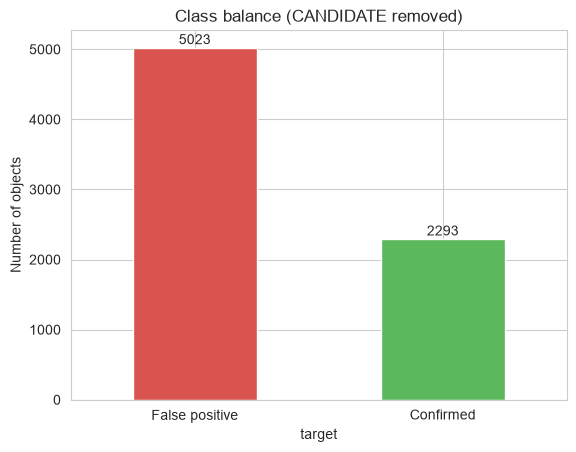

In [10]:
counts = data["target"].map({0: "False positive", 1: "Confirmed"}).value_counts()
ax = counts.plot(kind="bar", color=["#d9534f", "#5cb85c"], rot=0)
ax.set_title("Class balance (CANDIDATE removed)")
ax.set_ylabel("Number of objects")
for i, v in enumerate(counts):
    ax.text(i, v + 50, str(v), ha="center")
plt.show()

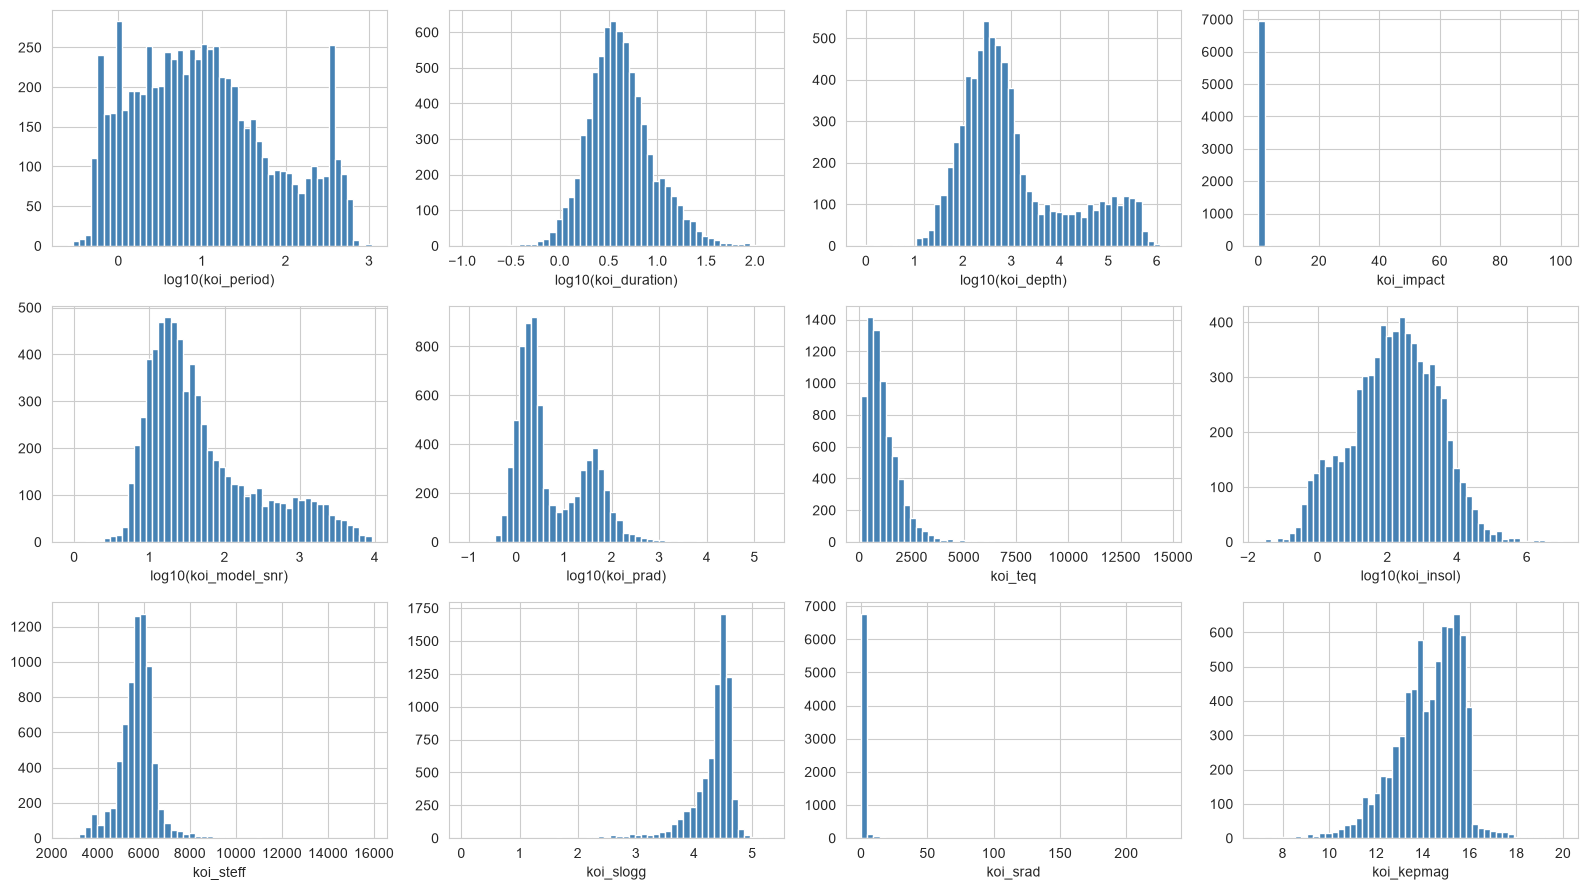

In [11]:
main_cols = ["koi_period", "koi_duration", "koi_depth", "koi_impact",
             "koi_model_snr", "koi_prad", "koi_teq", "koi_insol",
             "koi_steff", "koi_slogg", "koi_srad", "koi_kepmag"]
skewed = ["koi_period", "koi_depth", "koi_prad", "koi_model_snr", "koi_insol", "koi_duration"]

fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, col in zip(axes.ravel(), main_cols):
    x = data[col].dropna()
    if col in skewed:
        x = np.log10(x[x > 0])
        ax.set_xlabel(f"log10({col})")
    else:
        ax.set_xlabel(col)
    ax.hist(x, bins=50, color="steelblue")
plt.tight_layout()
plt.show()

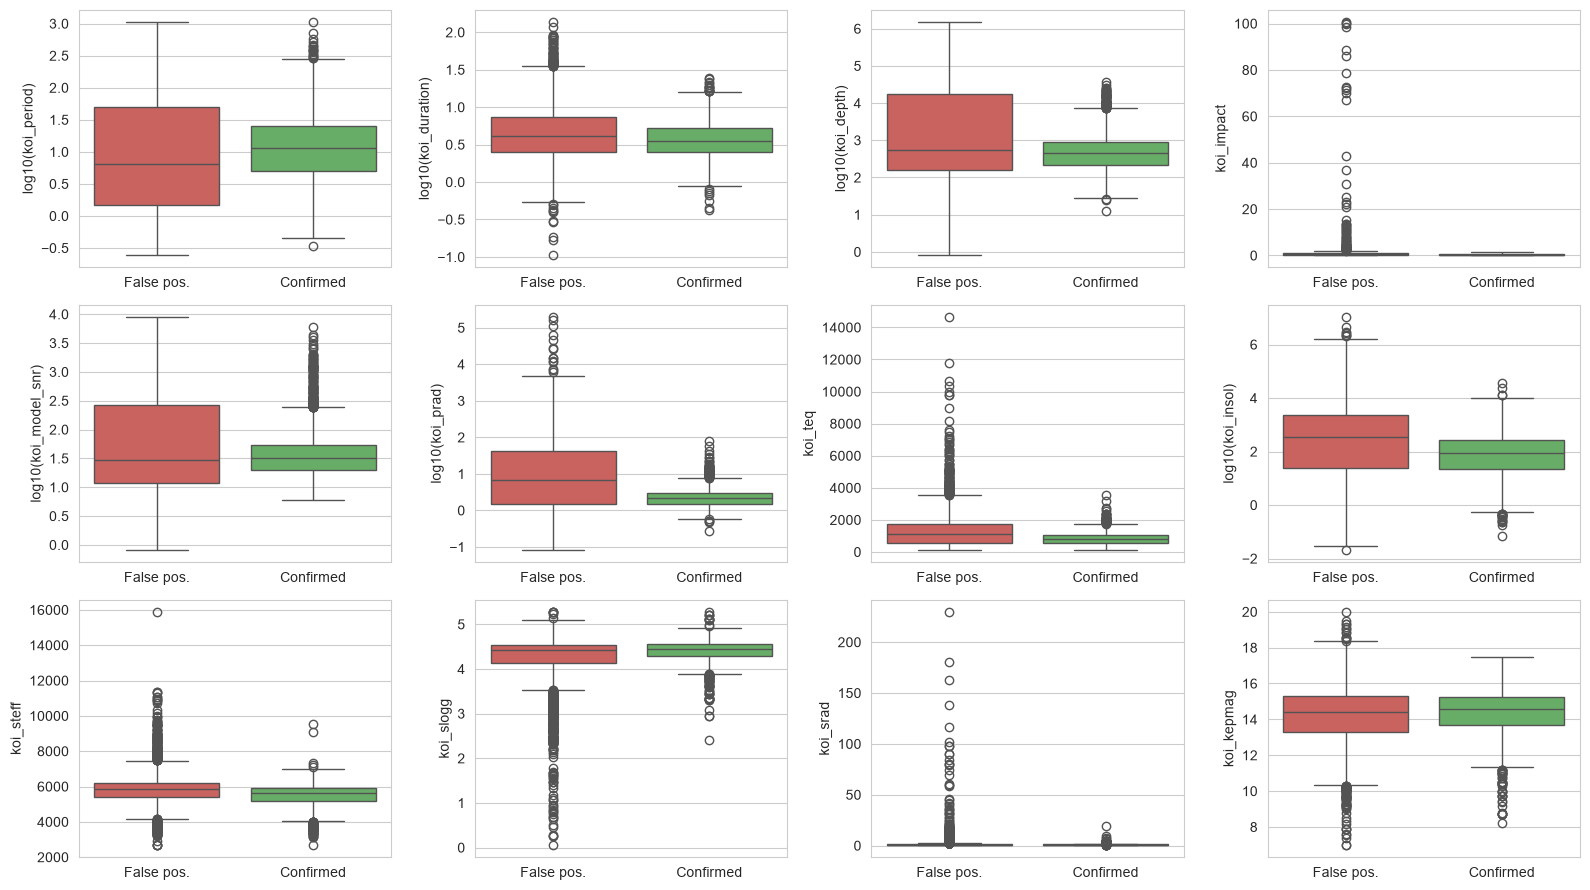

In [12]:
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, col in zip(axes.ravel(), main_cols):
    plot_df = data[[col, "target"]].dropna()
    if col in skewed:
        plot_df = plot_df[plot_df[col] > 0]
        plot_df[col] = np.log10(plot_df[col])
        label = f"log10({col})"
    else:
        label = col
    sns.boxplot(data=plot_df, x="target", y=col, ax=ax, palette=["#d9534f", "#5cb85c"], hue="target", legend=False)
    ax.set_ylabel(label)
    ax.set_xticks([0, 1], ["False pos.", "Confirmed"])
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

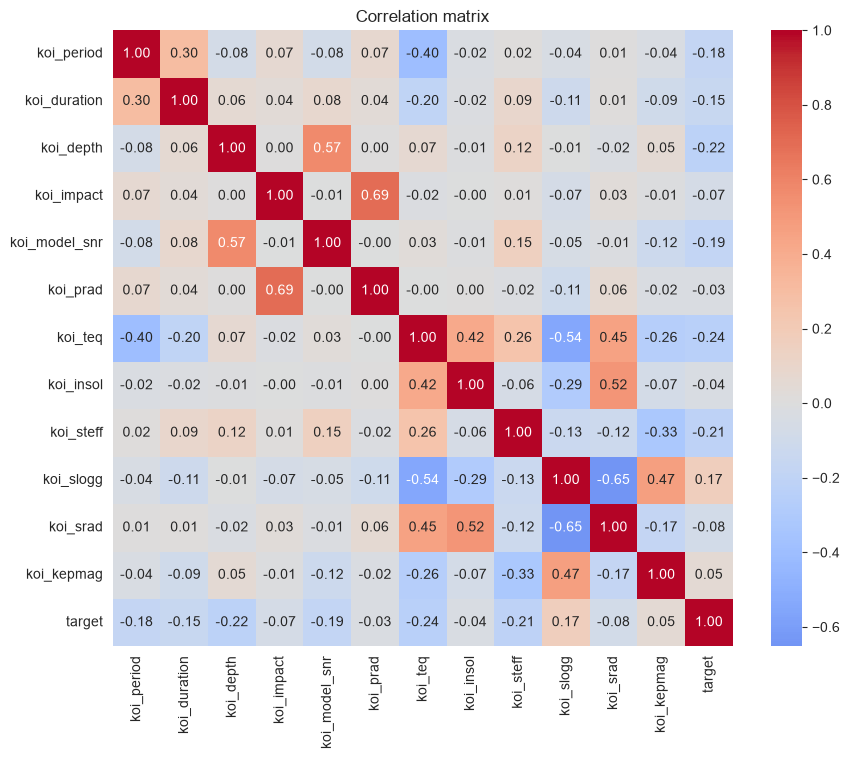

koi_teq         -0.24
koi_depth       -0.22
koi_steff       -0.21
koi_model_snr   -0.19
koi_period      -0.18
koi_slogg        0.17
koi_duration    -0.15
koi_srad        -0.08
koi_impact      -0.07
koi_kepmag       0.05
koi_insol       -0.04
koi_prad        -0.03
Name: target, dtype: float64


In [13]:
corr = data[main_cols + ["target"]].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

print(corr["target"].drop("target").sort_values(key=abs, ascending=False).round(2))


In [14]:
print(pd.crosstab(data["koi_tce_delivname"].fillna("missing"), data["target"], margins=True))
print()
print(pd.crosstab(data["koi_tce_plnt_num"], data["target"], normalize="index").round(2))

target                0     1   All
koi_tce_delivname                  
missing             271     8   279
q1_q16_tce          560     1   561
q1_q17_dr24_tce     216     3   219
q1_q17_dr25_tce    3976  2281  6257
All                5023  2293  7316

target               0     1
koi_tce_plnt_num            
1.0               0.73  0.27
2.0               0.36  0.64
3.0               0.31  0.69
4.0               0.24  0.76
5.0               0.42  0.58
6.0               0.67  0.33
7.0               0.86  0.14
8.0               1.00  0.00


In [15]:
# Fixed thresholds (chosen from astronomy, not learned from the data),
# so creating them before the split does not leak anything.
data["type_orbite"] = pd.cut(data["koi_period"], bins=[0, 10, 100, np.inf],
                             labels=["short", "medium", "long"]).astype(object)

data["type_planete"] = pd.cut(data["koi_prad"], bins=[0, 1.25, 2, 6, np.inf],
                              labels=["earth_like", "super_earth", "neptune_like", "jupiter_like"]).astype(object)

data["type_etoile"] = pd.cut(data["koi_steff"], bins=[0, 5200, 6000, np.inf],
                             labels=["cool", "sun_like", "hot"]).astype(object)

data["luminosite"] = pd.cut(data["koi_kepmag"], bins=[0, 13, 15, np.inf],
                            labels=["bright", "medium", "faint"]).astype(object)

new_cats = ["type_orbite", "type_planete", "type_etoile", "luminosite"]
for c in new_cats:
    print(data[c].value_counts(dropna=False), "\n")

type_orbite
short     3871
medium    2316
long      1129
Name: count, dtype: int64 

type_planete
jupiter_like    2552
neptune_like    1884
super_earth     1386
earth_like      1194
NaN              300
Name: count, dtype: int64 

type_etoile
sun_like    3181
hot         2412
cool        1423
NaN          300
Name: count, dtype: int64 

luminosite
medium    3472
faint     2562
bright    1281
NaN          1
Name: count, dtype: int64 



In [16]:
main_num = ["koi_period", "koi_time0bk", "koi_impact", "koi_duration", "koi_depth",
            "koi_prad", "koi_teq", "koi_insol", "koi_model_snr",
            "koi_steff", "koi_slogg", "koi_srad", "koi_kepmag"]

# Very spread-out columns: log transform before scaling
log_cols = ["koi_period", "koi_duration", "koi_depth", "koi_prad", "koi_model_snr", "koi_insol"]

y = data["target"]
X_main     = data[main_num + new_cats]                          # used by all models
X_ablation = data[main_num + new_cats + proxy_cols]             # only for the with/without experiment

print(X_main.shape, X_ablation.shape)

(7316, 17) (7316, 19)


In [17]:
from sklearn.model_selection import train_test_split

idx_train, idx_test = train_test_split(
    data.index, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

X_train, X_test = X_main.loc[idx_train], X_main.loc[idx_test]
Xa_train, Xa_test = X_ablation.loc[idx_train], X_ablation.loc[idx_test]
y_train, y_test = y.loc[idx_train], y.loc[idx_test]

print(X_train.shape, X_test.shape)
print(y_train.mean().round(3), y_test.mean().round(3))   # both should be about 0.313

(5852, 17) (1464, 17)
0.313 0.314


In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer

def make_preprocessor(num_cols, log_cols, cat_cols):
    plain_num = [c for c in num_cols if c not in log_cols]
    log_num   = [c for c in num_cols if c in log_cols]

    plain_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                           ("scaler", StandardScaler())])
    log_pipe   = Pipeline([("imputer", SimpleImputer(strategy="median")),
                       ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                       ("scaler", StandardScaler())])
    cat_pipe   = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                           ("onehot", OneHotEncoder(handle_unknown="ignore"))])

    return ColumnTransformer([("num", plain_pipe, plain_num),
                              ("lognum", log_pipe, log_num),
                              ("cat", cat_pipe, cat_cols)])

# Main version
prep_main = make_preprocessor(main_num, log_cols, new_cats)

# Ablation version: same + the two proxy columns
prep_ablation = make_preprocessor(main_num + ["koi_tce_plnt_num"], log_cols,
                                  new_cats + ["koi_tce_delivname"])

In [21]:
prep_main.fit(X_train)
Z = prep_main.transform(X_train)
print("Shape after preprocessing:", Z.shape)
print("Any missing values left:", np.isnan(Z).any())
print(prep_main.get_feature_names_out()[:10])

Shape after preprocessing: (5852, 26)
Any missing values left: False
['num__koi_time0bk' 'num__koi_impact' 'num__koi_teq' 'num__koi_steff'
 'num__koi_slogg' 'num__koi_srad' 'num__koi_kepmag' 'lognum__koi_period'
 'lognum__koi_duration' 'lognum__koi_depth']


In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

pipe = Pipeline([("prep", prep_main),
                 ("model", LogisticRegression(max_iter=1000))])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1")
print("F1 per fold:", scores.round(3), "| mean:", scores.mean().round(3))

F1 per fold: [0.809 0.813 0.812 0.804 0.785] | mean: 0.805


In [23]:
from sklearn.model_selection import cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, BaggingClassifier,
                              AdaBoostClassifier, GradientBoostingClassifier)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "k-NN":                KNeighborsClassifier(n_neighbors=5),
    "SVM (RBF)":           SVC(random_state=RANDOM_STATE),
    "Decision Tree":       DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "Bagging":             BaggingClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    "AdaBoost":            AdaBoostClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "Gradient Boosting":   GradientBoostingClassifier(random_state=RANDOM_STATE),
}

scoring = {"precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", prep_main), ("model", model)])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({"Model": name,
                 "Precision": res["test_precision"].mean(),
                 "Recall":    res["test_recall"].mean(),
                 "F1":        res["test_f1"].mean(),
                 "AUC-ROC":   res["test_roc_auc"].mean(),
                 "F1 std":    res["test_f1"].std()})
    print(f"done: {name}")

results = pd.DataFrame(rows).set_index("Model").sort_values("F1", ascending=False).round(3)
results

done: Logistic Regression
done: k-NN
done: SVM (RBF)
done: Decision Tree
done: Random Forest
done: Bagging
done: AdaBoost
done: Gradient Boosting


,Precision,Recall,F1,AUC-ROC,F1 std
Model,,,,,
Bagging,0.873,0.877,0.875,0.969,0.005
Gradient Boosting,0.866,0.880,0.873,0.972,0.007
Random Forest,0.875,0.870,0.872,0.973,0.006
SVM (RBF),0.855,0.884,0.869,0.967,0.008
AdaBoost,0.835,0.853,0.844,0.958,0.006
k-NN,0.783,0.860,0.820,0.933,0.008
Decision Tree,0.808,0.818,0.813,0.865,0.020
Logistic Regression,0.807,0.803,0.805,0.940,0.010


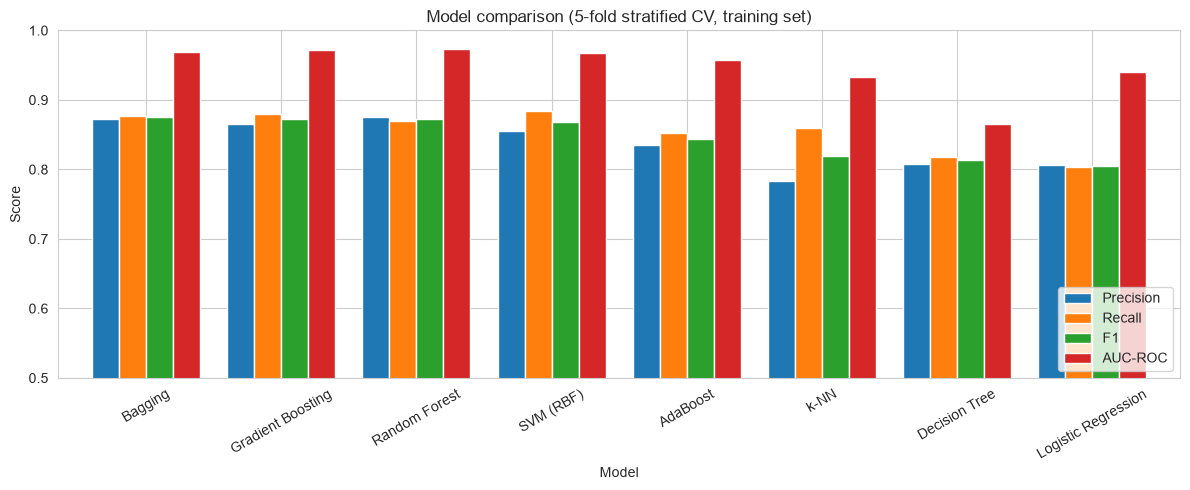

In [24]:
ax = results[["Precision", "Recall", "F1", "AUC-ROC"]].plot(
    kind="bar", figsize=(12, 5), rot=30, width=0.8)
ax.set_title("Model comparison (5-fold stratified CV, training set)")
ax.set_ylabel("Score")
ax.set_ylim(0.5, 1.0)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [25]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

search_spaces = {
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE),
        {"model__n_estimators": randint(200, 600),
         "model__max_depth": [None, 10, 20, 30],
         "model__min_samples_leaf": randint(1, 6),
         "model__max_features": ["sqrt", "log2", 0.5]}),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=RANDOM_STATE),
        {"model__n_estimators": randint(100, 500),
         "model__learning_rate": uniform(0.02, 0.18),   # 0.02 to 0.20
         "model__max_depth": randint(2, 6),
         "model__subsample": uniform(0.6, 0.4)}),       # 0.6 to 1.0
}

best, cv_f1 = {}, {}
for name, (model, space) in search_spaces.items():
    pipe = Pipeline([("prep", prep_main), ("model", model)])
    rs = RandomizedSearchCV(pipe, space, n_iter=20, scoring="f1", cv=cv,
                            random_state=RANDOM_STATE, n_jobs=-1)
    rs.fit(X_train, y_train)
    best[name], cv_f1[name] = rs.best_estimator_, rs.best_score_
    print(f"{name}: best CV F1 = {rs.best_score_:.3f}")
    print(rs.best_params_, "\n")

Random Forest: best CV F1 = 0.881
{'model__max_depth': 20, 'model__max_features': 0.5, 'model__min_samples_leaf': 1, 'model__n_estimators': 249} 

Gradient Boosting: best CV F1 = 0.892
{'model__learning_rate': np.float64(0.06658039668800304), 'model__max_depth': 5, 'model__n_estimators': 487, 'model__subsample': np.float64(0.7246844304357644)} 



Random Forest
                precision    recall  f1-score   support

False positive      0.943     0.954     0.949      1005
     Confirmed      0.897     0.874     0.885       459

      accuracy                          0.929      1464
     macro avg      0.920     0.914     0.917      1464
  weighted avg      0.929     0.929     0.929      1464

Gradient Boosting
                precision    recall  f1-score   support

False positive      0.952     0.955     0.954      1005
     Confirmed      0.901     0.895     0.898       459

      accuracy                          0.936      1464
     macro avg      0.927     0.925     0.926      1464
  weighted avg      0.936     0.936     0.936      1464



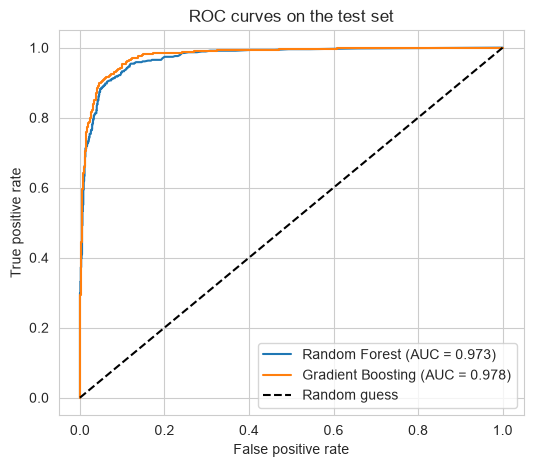

In [26]:
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score)

fig, ax = plt.subplots(figsize=(6, 5))
for name, est in best.items():
    proba = est.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
    print(name)
    print(classification_report(y_test, est.predict(X_test),
                                target_names=["False positive", "Confirmed"], digits=3))
ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC curves on the test set"); ax.legend(loc="lower right")
plt.show()

Final model: Gradient Boosting


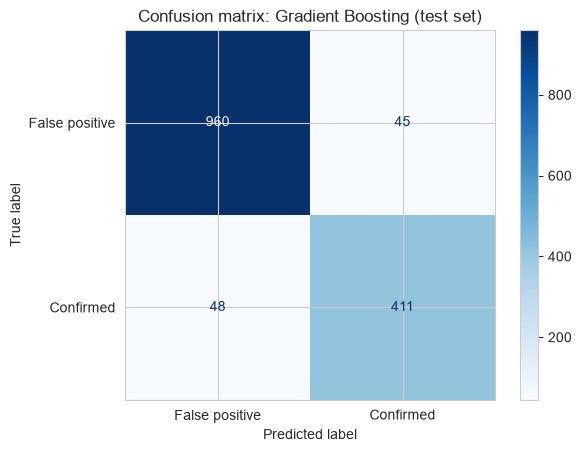

In [27]:
final_name = max(cv_f1, key=cv_f1.get)     # chosen by CV score, not by test score
print("Final model:", final_name)
ConfusionMatrixDisplay.from_estimator(
    best[final_name], X_test, y_test,
    display_labels=["False positive", "Confirmed"], cmap="Blues")
plt.title(f"Confusion matrix: {final_name} (test set)")
plt.show()

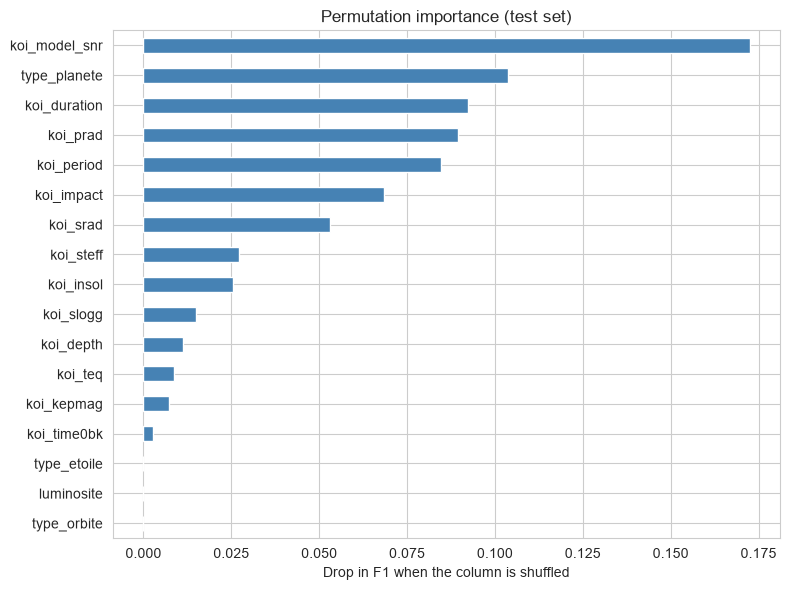

koi_model_snr    0.1725
type_planete     0.1036
koi_duration     0.0924
koi_prad         0.0895
koi_period       0.0845
koi_impact       0.0684
koi_srad         0.0531
koi_steff        0.0271
koi_insol        0.0255
koi_slogg        0.0148
koi_depth        0.0112
koi_teq          0.0088
koi_kepmag       0.0072
koi_time0bk      0.0027
type_etoile      0.0000
luminosite       0.0000
type_orbite     -0.0001
dtype: float64


In [28]:
from sklearn.inspection import permutation_importance

r = permutation_importance(best[final_name], X_test, y_test, scoring="f1",
                           n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(r.importances_mean, index=X_test.columns).sort_values()

imp.plot(kind="barh", figsize=(8, 6), color="steelblue")
plt.xlabel("Drop in F1 when the column is shuffled")
plt.title("Permutation importance (test set)")
plt.tight_layout()
plt.show()
print(imp.sort_values(ascending=False).round(4))

In [29]:
from sklearn.base import clone
from sklearn.metrics import f1_score

gb = best["Gradient Boosting"].named_steps["model"]   # tuned settings

def evaluate(prep, Xtr, Xte, label):
    pipe = Pipeline([("prep", prep), ("model", clone(gb))])
    cv_f1 = cross_val_score(pipe, Xtr, y_train, cv=cv, scoring="f1").mean()
    pipe.fit(Xtr, y_train)
    proba = pipe.predict_proba(Xte)[:, 1]
    return {"Version": label, "CV F1": cv_f1,
            "Test F1": f1_score(y_test, pipe.predict(Xte)),
            "Test AUC": roc_auc_score(y_test, proba)}

ablation = pd.DataFrame([
    evaluate(prep_main,     X_train,  X_test,  "Without proxy columns (main)"),
    evaluate(prep_ablation, Xa_train, Xa_test, "With koi_tce_delivname + koi_tce_plnt_num"),
]).set_index("Version").round(3)
ablation

,CV F1,Test F1,Test AUC
Version,,,
Without proxy columns (main),0.892,0.898,0.978
With koi_tce_delivname + koi_tce_plnt_num,0.892,0.899,0.978
